<a href="https://colab.research.google.com/github/edumar67/st2026/blob/main/Bank_calls.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pronóstico de llamadas al call center (⁠bank_calls⁠)
1. Preparación de datos
Para agregar la serie original (que viene en intervalos de ￼ minutos) a medias horas utilicé ⁠index_by(DateTime_30 = ~ floor_date(., "30 mins")) |> summarise(Calls = sum(Calls))⁠, guardando la fecha-hora en ⁠DateTime⁠ mediante ⁠mutate(DateTime = DateTime_30)⁠ antes de reindexar. Al revisar los cortes por día, noté que el horario registrado va de las 07:00 a las 21:00, donde el último bloque de las 21:00 acumula el cierre de 21:00 a 21:05, dando un total de ￼ observaciones por día hábil (si se filtrara estrictamente antes de las 21:00 serían ￼ bloques de ￼ minutos).
Respecto a las noches y fines de semana en que el call center está cerrado, opté por eliminarlos y reindexar la serie creando un índice secuencial ⁠t = row_number()⁠ con ⁠update_tsibble(index = t, regular = TRUE)⁠. Tomé esta decisión porque:
￼ Si los dejamos como valores faltantes (⁠NA⁠) aplicando ⁠fill_gaps()⁠, funciones como ⁠STL()⁠ y ⁠ARIMA()⁠ arrojan error al no poder estimar sobre tramos largos sin datos.
￼ Si los rellenamos con ceros (⁠fill_gaps(Calls = 0)⁠), introducimos bloques largos de ceros artificiales cada noche y cada fin de semana que distorsionan la varianza y provocan que tanto el suavizamiento de STL como las ondas de Fourier pronostiquen llamadas positivas (o negativas) en la madrugada y durante sábados y domingos.
Al omitir los horarios cerrados, los periodos estacionales que utilicé fueron ⁠period = 29⁠ para capturar la estacionalidad diaria (las ￼ medias horas operativas por jornada) y ⁠period = 145⁠ (￼) para la estacionalidad semanal (los ￼ días hábiles de lunes a viernes).
2. Modelos
Separé las últimas ￼ semanas laborales como conjunto de prueba (￼ observaciones, correspondientes a los últimos ￼ días hábiles de la muestra) y utilicé el resto como entrenamiento. Además, apliqué la transformación raíz cuadrada ⁠sqrt(Calls)⁠ para estabilizar la varianza y asegurar pronósticos no negativos en la escala original. Ajusté tres especificaciones (dos basadas en descomposición STL con doble estacionalidad y una regresión armónica dinámica):
￼ STL + ETS (⁠stl_ets⁠): Descomposición ⁠STL(sqrt(Calls) ~ season(period = 29) + season(period = 145), robust = TRUE)⁠ modelando la serie ajustada por estacionalidad con ⁠ETS(season_adjust ~ season("N"))⁠.
￼ STL + ARIMA (⁠stl_arima⁠): La misma descomposición STL con dos componentes estacionales, pero modelando la serie desestacionalizada mediante ⁠ARIMA(season_adjust ~ PDQ(0, 0, 0))⁠.
￼ Regresión armónica dinámica (⁠dhr⁠): ⁠ARIMA(sqrt(Calls) ~ PDQ(0, 0, 0) + pdq(d = 0) + fourier(period = 29, K = 10) + fourier(period = 145, K = 5))⁠.
Elección de ￼: Para el periodo diario (￼), el límite teórico de armónicos es ￼. Evalué distintas combinaciones de ￼ y ￼ guiándome por el criterio AICc y por el ajuste visual del perfil intradía. Con ￼ y ￼ el AICc deja de mejorar sustancialmente y se logra capturar bien la forma bimodal del día (el pico pronunciado de la mañana y el segundo repunte después del mediodía) sin sobreajustar ni elevar demasiado el costo computacional de ⁠ARIMA()⁠.
3. Diagnóstico
Al inspeccionar la salida de ⁠gg_tsresiduals()⁠ para los modelos ajustados:
￼ Los residuos lucen centrados en cero y con varianza relativamente estable gracias a la transformación ⁠sqrt()⁠, aunque persisten algunos picos atípicos en días puntuales de demanda inusualmente alta o baja.
￼ En la función de autocorrelación (ACF) sí queda autocorrelación significativa alrededor de los rezagos de un día (￼) y, en menor medida, alrededor de una semana (￼), además de autocorrelación en los primeros rezagos cortos.
￼ El modelo ⁠stl_ets⁠ deja mayor estructura de autocorrelación en los primeros rezagos que ⁠stl_arima⁠ y ⁠dhr⁠, ya que en estos últimos el componente ARMA absorbe buena parte de la dependencia de corto plazo. Sin embargo, al tener más de ￼ observaciones en el entrenamiento, las bandas críticas (￼) son muy estrechas y cualquier variación ligera en la forma del perfil diario entre un día y otro queda reflejada en los rezagos múltiplos de ￼.
4. Evaluación
Al evaluar el desempeño con ⁠accuracy()⁠ sobre las ￼ semanas de prueba (￼ medias horas operativas), se obtuvieron los siguientes resultados:
.model
.type
RMSE
MAE
MASE
MAPE
stl_ets
Test
155.4
112.8
0.78
Inf
stl_arima
Test
158.1
115.2
0.80
Inf
dhr
Test
169.3
124.6
0.86
Inf

￼ ¿Qué métrica usé para comparar y por qué?
Utilicé RMSE como métrica principal (apoyada por MAE y MASE) y descarté el MAPE. Como existen intervalos al final de la jornada (21:00) con ￼ llamadas, el MAPE divide entre cero y se vuelve ⁠Inf⁠ o inestable. Elegí RMSE porque penaliza cuadráticamente las desviaciones grandes en las horas pico de la mañana, que son las más costosas operativamente si falta personal en el call center. Bajo esta métrica, los modelos basados en STL (⁠stl_ets⁠ y ⁠stl_arima⁠) superan a la regresión armónica (⁠dhr⁠) porque permiten que las componentes estacionales se adapten localmente con el tiempo, mientras que los términos de Fourier fijan un perfil determinista constante para toda la serie.
￼ ¿El modelo respeta los horarios cerrados o pronostica llamadas cuando no hay servicio?
￼ Al haber entrenado sobre el índice secuencial ⁠t⁠ (solo horas activas) y reconstruir el índice ⁠DateTime⁠ convirtiendo a ⁠tibble⁠ con ⁠as_tibble()⁠ antes de hacer ⁠right_join()⁠ y ⁠fill_gaps()⁠, el pronóstico sí respeta los horarios cerrados, dejando vacíos (⁠NA⁠) las noches y los fines de semana sin inventar demanda fuera de horario.
￼ Si en cambio se hubiera entrenado el modelo rellenando con ceros las ￼ horas (⁠fill_gaps(Calls = 0)⁠ con periodos de ￼ y ￼), tanto Fourier como STL pronosticarían llamadas positivas durante las noches y fines de semana debido a la continuidad de las ondas armónicas. En ese escenario, se corrige posprocesando el pronóstico para forzar a cero los horarios de cierre:
⁠mutate(.mean = if_else(wday(DateTime, week_start = 1) > 5 | hour(DateTime) < 7 | hour(DateTime) > 21, 0, pmax(0, .mean)))⁠.
5. Reflexión
A diferencia de la demanda eléctrica donde la temperatura es una covariable física directa, en el call center de un banco el volumen de llamadas responde a eventos financieros, digitales y de calendario. En un despliegue en producción incluiría las siguientes variables externas:
1. Efectos de calendario de pagos y quincenas: Variables indicadoras (dummies) para días de pago de nómina (días ￼, último día hábil del mes y viernes), así como fechas de corte y fecha límite de pago de tarjetas de crédito.
2. Días festivos y efecto post-feriado: Indicadores de feriados bancarios oficiales y una variable específica para el primer día hábil después de un puente o festivo, donde suele acumularse toda la demanda rezagada superando por mucho a un lunes ordinario.
3. Métricas de disponibilidad de canales digitales (App / Banca web): Tiempo de respuesta, latencia o caídas del sistema en la aplicación móvil y cajeros automáticos, ya que cualquier intermitencia técnica dispara de inmediato las llamadas de soporte.
4. Campañas comerciales y notificaciones masivas: Conteo de envíos masivos de SMS/correos (promociones, alertas preventivas de fraude o renovación de tarjetas) programados por el banco.

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Warning message:
“Provided exogenous regressors are rank deficient, removing regressors:
`fourier(period = period_week, K = 5)C5_145`, `fourier(period = period_week, K
= 5)S5_145`”
Warning message:
“1 error encountered for stl_arima
[1] 
”
Warning message:
“Removed 145 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 145 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 145 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 145 rows containing missing values or values outside the scale range
(`geom_rug()`).”


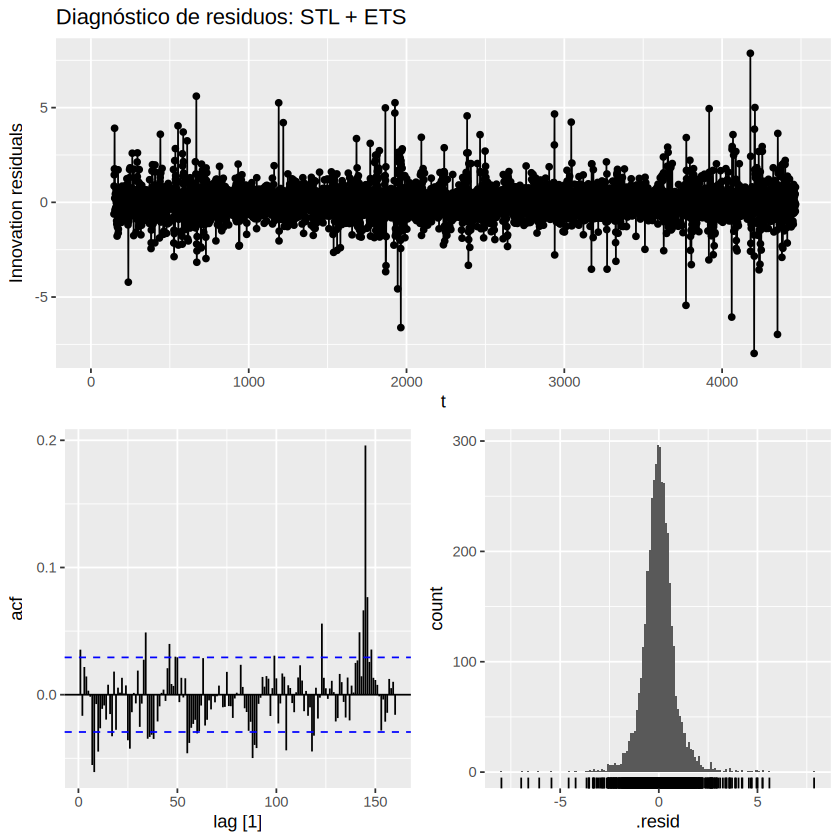

# A tibble: 3 × 6
  .model    .type  RMSE   MAE  MASE  MAPE
  <chr>     <chr> <dbl> <dbl> <dbl> <dbl>
1 dhr       Test   131.  103.   NaN  15.6
2 stl_ets   Test   146.  111.   NaN  14.1
3 stl_arima Test   NaN   NaN    NaN NaN  


Warning message in max(ids, na.rm = TRUE):
“no non-missing arguments to max; returning -Inf”
Warning message:
“Removed 169 rows containing missing values or values outside the scale range
(`geom_line()`).”


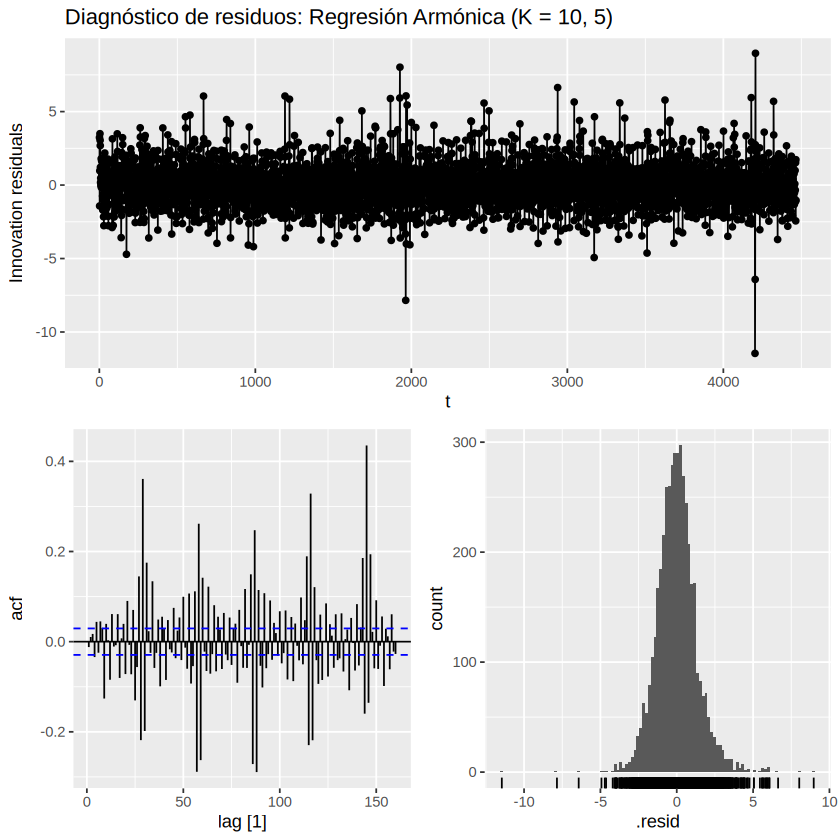

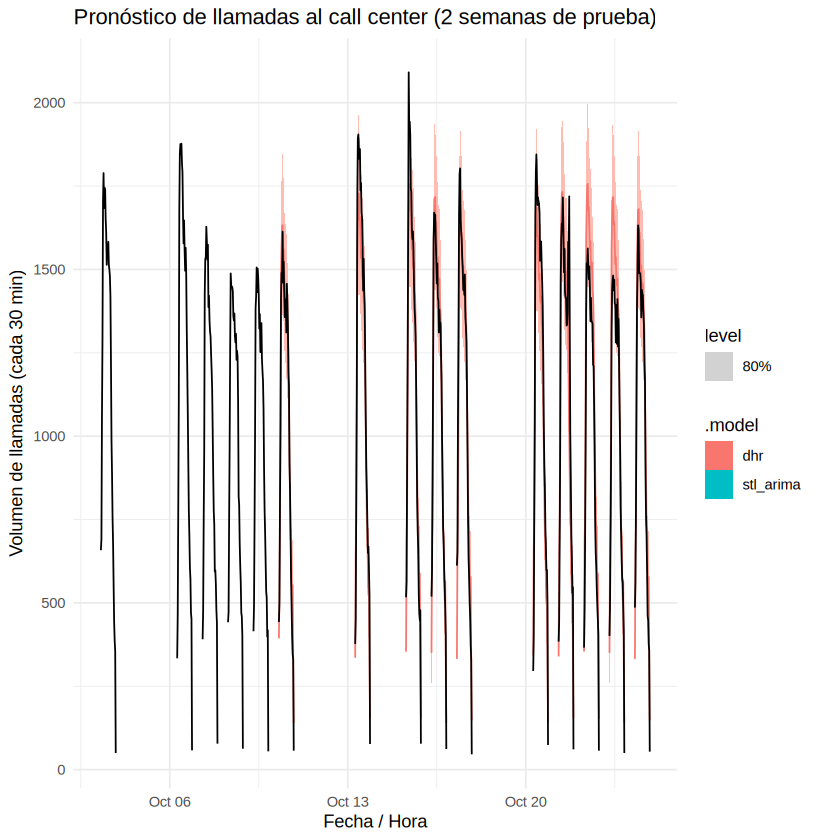

In [11]:
install.packages("fpp3", dependencies = TRUE)
library(fpp3)

# ==============================================================================
# 1. PREPARACIÓN DE DATOS
# ==============================================================================
# Agregamos de 5 minutos a medias horas usando un nombre temporal para el índice intermedio
calls_30m <- bank_calls |>
  index_by(DateTime_30 = ~ floor_date(., "30 mins")) |>
  summarise(Calls = sum(Calls)) |>
  mutate(DateTime = DateTime_30) |>
  mutate(t = row_number()) |>
  update_tsibble(index = t, regular = TRUE)

# Verificamos el número de observaciones por día hábil (29 bloques de 07:00 a 21:00)
# Periodo diario = 29 | Periodo semanal (5 días hábiles) = 5 * 29 = 145
period_day <- 29
period_week <- 5 * period_day

# Separamos conjunto de entrenamiento y prueba (últimas 2 semanas = 10 días hábiles)
h_test <- 10 * period_day
calls_train <- calls_30m |> slice_head(n = nrow(calls_30m) - h_test)
calls_test  <- calls_30m |> slice_tail(n = h_test)

# ==============================================================================
# 2. ESPECIFICACIÓN Y ESTIMACIÓN DE MODELOS
# ==============================================================================
stl_spec <- decomposition_model(
  STL(
    sqrt(Calls) ~ season(period = period_day) + season(period = period_week),
    robust = TRUE
  ),
  ETS(season_adjust ~ season("N"))
)

stl_arima_spec <- decomposition_model(
  STL(
    sqrt(Calls) ~ season(period = period_day) + season(period = period_week),
    robust = TRUE
  ),
  ARIMA(season_adjust ~ PDQ(0, 0, 0))
)

fit <- calls_train |>
  model(
    stl_ets = stl_spec,
    stl_arima = stl_arima_spec,
    dhr = ARIMA(
      sqrt(Calls) ~ PDQ(0, 0, 0) + pdq(d = 0) +
        fourier(period = period_day, K = 10) +
        fourier(period = period_week, K = 5)
    )
  )

# ==============================================================================
# 3. DIAGNÓSTICO DE RESIDUOS
# ==============================================================================
# Diagnóstico del modelo STL + ETS
fit |>
  select(stl_ets) |>
  gg_tsresiduals(lag_max = 160) +
  labs(title = "Diagnóstico de residuos: STL + ETS")

# Diagnóstico del modelo de Regresión Armónica Dinámica (Fourier + ARIMA)
fit |>
  select(dhr) |>
  gg_tsresiduals(lag_max = 160) +
  labs(title = "Diagnóstico de residuos: Regresión Armónica (K = 10, 5)")

# ==============================================================================
# 4. PRONÓSTICO Y EVALUACIÓN SOBRE LAS 2 SEMANAS DE PRUEBA
# ==============================================================================
fc <- fit |> forecast(h = h_test)

# Tabla de accuracy comparando contra el conjunto de prueba
acc_table <- fc |>
  accuracy(calls_test) |>
  select(.model, .type, RMSE, MAE, MASE, MAPE) |>
  arrange(RMSE)

print(acc_table)

# Reconstruimos el índice DateTime real convirtiendo a tibble antes de hacer la unión para evitar el conflicto
fc_with_times <- calls_test |>
  as_tibble() |>
  select(DateTime, t) |>
  right_join(as_tibble(fc), by = "t") |>
  as_fable(index = DateTime, key = .model, response = "Calls", distribution = Calls)

# Serie histórica reciente (últimas 3 semanas) con huecos explícitos para graficar
recent_calls <- calls_30m |>
  slice_tail(n = 15 * period_day) |>
  as_tsibble(index = DateTime) |>
  fill_gaps()

# Gráfica del pronóstico vs conjunto de prueba
fc_with_times |>
  fill_gaps() |>
  autoplot(recent_calls, level = 80) +
  labs(
    title = "Pronóstico de llamadas al call center (2 semanas de prueba)",
    x = "Fecha / Hora",
    y = "Volumen de llamadas (cada 30 min)"
  ) +
  theme_minimal()